# Phase 1 Complete Analysis — UCI Heart Disease Dataset (`heart_disease`)

**Source:** [UCI Machine Learning Repository (ID 45)](https://archive.ics.uci.edu/dataset/45/heart+disease) / [Direct CSV](https://raw.githubusercontent.com/sharmaroshan/Heart-UCI-Dataset/master/heart.csv)  
**Domain & Goal:** Cleveland clinical cardiology dataset (`303` raw rows × `14` columns; target: `target` [`0`/`1`]). Key challenges include small-integer nominal clinical codes (`cp`, `restecg`, `slope`, `thal`), zero-inflated `oldpeak`, and extreme cholesterol outliers (`chol = 564 mg/dL`).

---
## 1. Dataset Overview & Semantic Column Profiling
**What we did & why:** We loaded the raw CSV using string-first two-pass ingestion (`ads.ingestion.load_csv`) so pandas never silently coerces formatting quirks, verified the raw file SHA-256 checksum, and classified every column into one of 10 semantic types (`numeric_continuous`, `numeric_discrete`, `binary`, `categorical_nominal`, `categorical_ordinal`, `datetime`, `id_like`, `free_text`, `constant`, `unknown`).

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

DATASET = "heart_disease"
OUT_DIR = Path("..") / "outputs" / DATASET
CLEAN_CSV = Path("..") / "data" / "cleaned" / f"{DATASET}_cleaned.csv"
IMPUTED_CSV = Path("..") / "data" / "cleaned" / f"{DATASET}_cleaned_imputed.csv"

prof = json.loads((OUT_DIR / "profile.json").read_text(encoding="utf-8"))
print(f"Dataset: {prof['dataset_name']} | Raw shape: {prof['n_rows']:,} rows x {prof['n_cols']} cols | Exact duplicates: {prof['n_duplicate_rows']}")
prof_df = pd.DataFrame(prof["columns"])[["name", "raw_dtype", "semantic_type", "pct_missing", "n_unique", "semantic_type_reason"]]
display(prof_df)

Dataset: heart_disease | Raw shape: 303 rows x 14 cols | Exact duplicates: 1


name,raw_dtype,semantic_type,pct_missing,n_unique,semantic_type_reason
age,int64,numeric_continuous,0.0%,41,"numeric values (100.0% parseable, 41 unique)"
sex,int64,binary,0.0%,2,"numeric with two values (0, 1)"
cp,int64,categorical_nominal,0.0%,4,config override: forced_types['cp'] = categorical_nominal
trestbps,int64,numeric_continuous,0.0%,49,"numeric values (100.0% parseable, 49 unique)"
chol,int64,numeric_continuous,0.0%,152,"numeric values (100.0% parseable, 152 unique)"
fbs,int64,binary,0.0%,2,"numeric with two values (0, 1)"
restecg,int64,categorical_nominal,0.0%,3,config override: forced_types['restecg'] = categorical_nominal
thalach,int64,numeric_continuous,0.0%,91,"numeric values (100.0% parseable, 91 unique)"
exang,int64,binary,0.0%,2,"numeric with two values (0, 1)"
oldpeak,float64,numeric_continuous,0.0%,40,"numeric values (100.0% parseable, 40 unique)"


## 2. Automated Data Cleaning & Step-by-Step Audit Log
**What we did & why:** We executed the 12-step deterministic cleaning pipeline (`ads.cleaning.clean_dataset`):
1. **Header & Whitespace/Unicode Normalization:** Stripped leading/trailing spaces and invisible characters.
2. **Missing Placeholder Normalization:** Converted placeholder tokens (`'?'`, `'N/A'`, `'null'`, `''`, and configured `'unknown'`) to `NaN`.
3. **Category Standardization & Type Conversion:** Unified case variants, parsed formatted numeric strings, and enforced domain validity ranges.
4. **Duplicate & Structural Drops:** Removed exact duplicate rows and redundant index/empty columns.
5. **Dual Missingness & Outlier Policy:** Saved both the **conservative primary dataset** (`_cleaned.csv`, preserving `NaN` and flagging $1.5\times\text{IQR}$ outliers without deleting valid extremes) and the **imputed secondary dataset** (`_cleaned_imputed.csv` with `__was_missing` indicator flags).

In [2]:
# Display the step-by-step cleaning audit log with before/after cell examples
display(Markdown((OUT_DIR / "cleaning_log.md").read_text(encoding="utf-8")))

# Cleaning Log — `heart_disease`

## Summary
2 cleaning step group(s) recorded; 0 column(s) type-converted; 0 cell(s) normalized (whitespace/missing tokens/categories); 1 duplicate row(s) removed; 0 row(s) dropped for structural/missingness rules.

## Step-by-Step Log

| Step | Column | Action | Severity | Cells Affected | Rows (Before -> After) | Reason | Examples (Before -> After) |
| :--- | :--- | :--- | :--- | ---: | ---: | :--- | :--- |
| `handle_duplicates` | *(table)* | `dropped_duplicate_rows` | info | 14 | 303 -> 302 | Dropped 1 exact duplicate row(s) (kept first occurrence). | - |
| `handle_outliers` | `trestbps` | `flagged_outliers` | info | 0 | 302 -> 302 | Flagged 9 outlier(s) (3.0%) and 0 extreme outlier(s) in 'trestbps' (action=flag; values untouched). | `172` -> `172`; `178` -> `178`; `180` -> `180` |
| `handle_outliers` | `chol` | `flagged_outliers` | info | 0 | 302 -> 302 | Flagged 5 outlier(s) (1.7%) and 1 extreme outlier(s) in 'chol' (action=flag; values untouched). | `417` -> `417`; `564` -> `564`; `394` -> `394` |
| `handle_outliers` | `thalach` | `flagged_outliers` | info | 0 | 302 -> 302 | Flagged 1 outlier(s) (0.3%) and 0 extreme outlier(s) in 'thalach' (action=flag; values untouched). | `71` -> `71` |
| `handle_outliers` | `oldpeak` | `flagged_outliers` | info | 0 | 302 -> 302 | Flagged 5 outlier(s) (1.7%) and 0 extreme outlier(s) in 'oldpeak' (action=flag; values untouched). | `4.2` -> `4.2`; `6.2` -> `6.2`; `5.6` -> `5.6` |
| `handle_outliers` | `ca` | `flagged_outliers` | info | 0 | 302 -> 302 | Flagged 24 outlier(s) (7.9%) and 0 extreme outlier(s) in 'ca' (action=flag; values untouched). | `3` -> `3`; `4` -> `4`; `3` -> `3` |


## 3. Cleaned Dataset Preview (Conservative vs. Imputed)
**What we did & why:** Below we inspect the first 5 rows and shapes of both the conservative cleaned dataset (`NaN` preserved for unbiased statistical testing) and the imputed dataset (median/mode imputed with `__was_missing` binary indicators).

In [3]:
df_clean = pd.read_csv(CLEAN_CSV)
df_imputed = pd.read_csv(IMPUTED_CSV)
print(f"Conservative cleaned shape: {df_clean.shape} | Imputed cleaned shape: {df_imputed.shape}")
display(df_clean.head(5))

Conservative cleaned shape: (302, 14) | Imputed cleaned shape: (302, 14)


age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
63.0,1,3,145.0,233.0,1,0,150.0,0,2.3,0,0,1,1
37.0,1,2,130.0,250.0,0,1,187.0,0,3.5,0,0,2,1
41.0,0,1,130.0,204.0,0,0,172.0,0,1.4,2,0,2,1
56.0,1,1,120.0,236.0,0,1,178.0,0,0.8,2,0,2,1
57.0,0,0,120.0,354.0,0,1,163.0,1,0.6,2,0,2,1


## 4. Exploratory Data Analysis (EDA) & Visualizations
**What we did & why:** Using `ads.eda.run_eda`, we generated 150-DPI static PNG visualizations covering dataset overview, missingness patterns, univariate numeric histograms + KDEs, IQR boxplots, categorical frequency distributions, target class balance, and bivariate relationships (Pearson $r$ / Spearman $\rho$ correlation heatmaps, bias-corrected Cramér's $V$, and $\eta^2$ group breakdowns). Every chart is paired below with a note explaining what it reveals about the data.

#### 14 columns; the most common type is numeric_continuous (5 columns)
*Figure 1. 14 columns; the most common type is numeric_continuous (5 columns).* Count of columns by the semantic type the pipeline inferred (after cleaning).


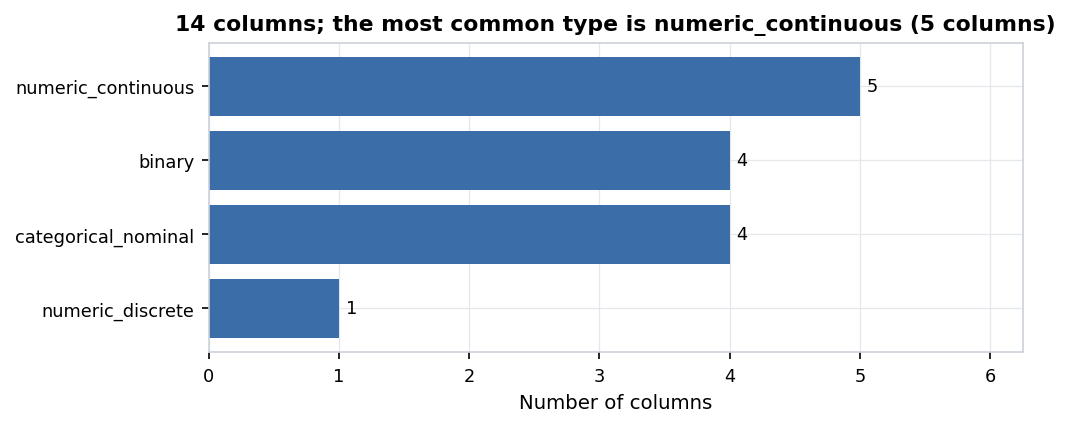

#### Numeric distributions (1/1): most skewed here is 'ca' (skew +1.30)
*Figure 2. Numeric distributions (1/1): most skewed here is 'ca' (skew +1.30).* Histogram (with a smooth density curve for many-valued columns) and a box plot per column. Orange line = mean, green dashed line = median; red dots are values beyond 1.5×IQR.


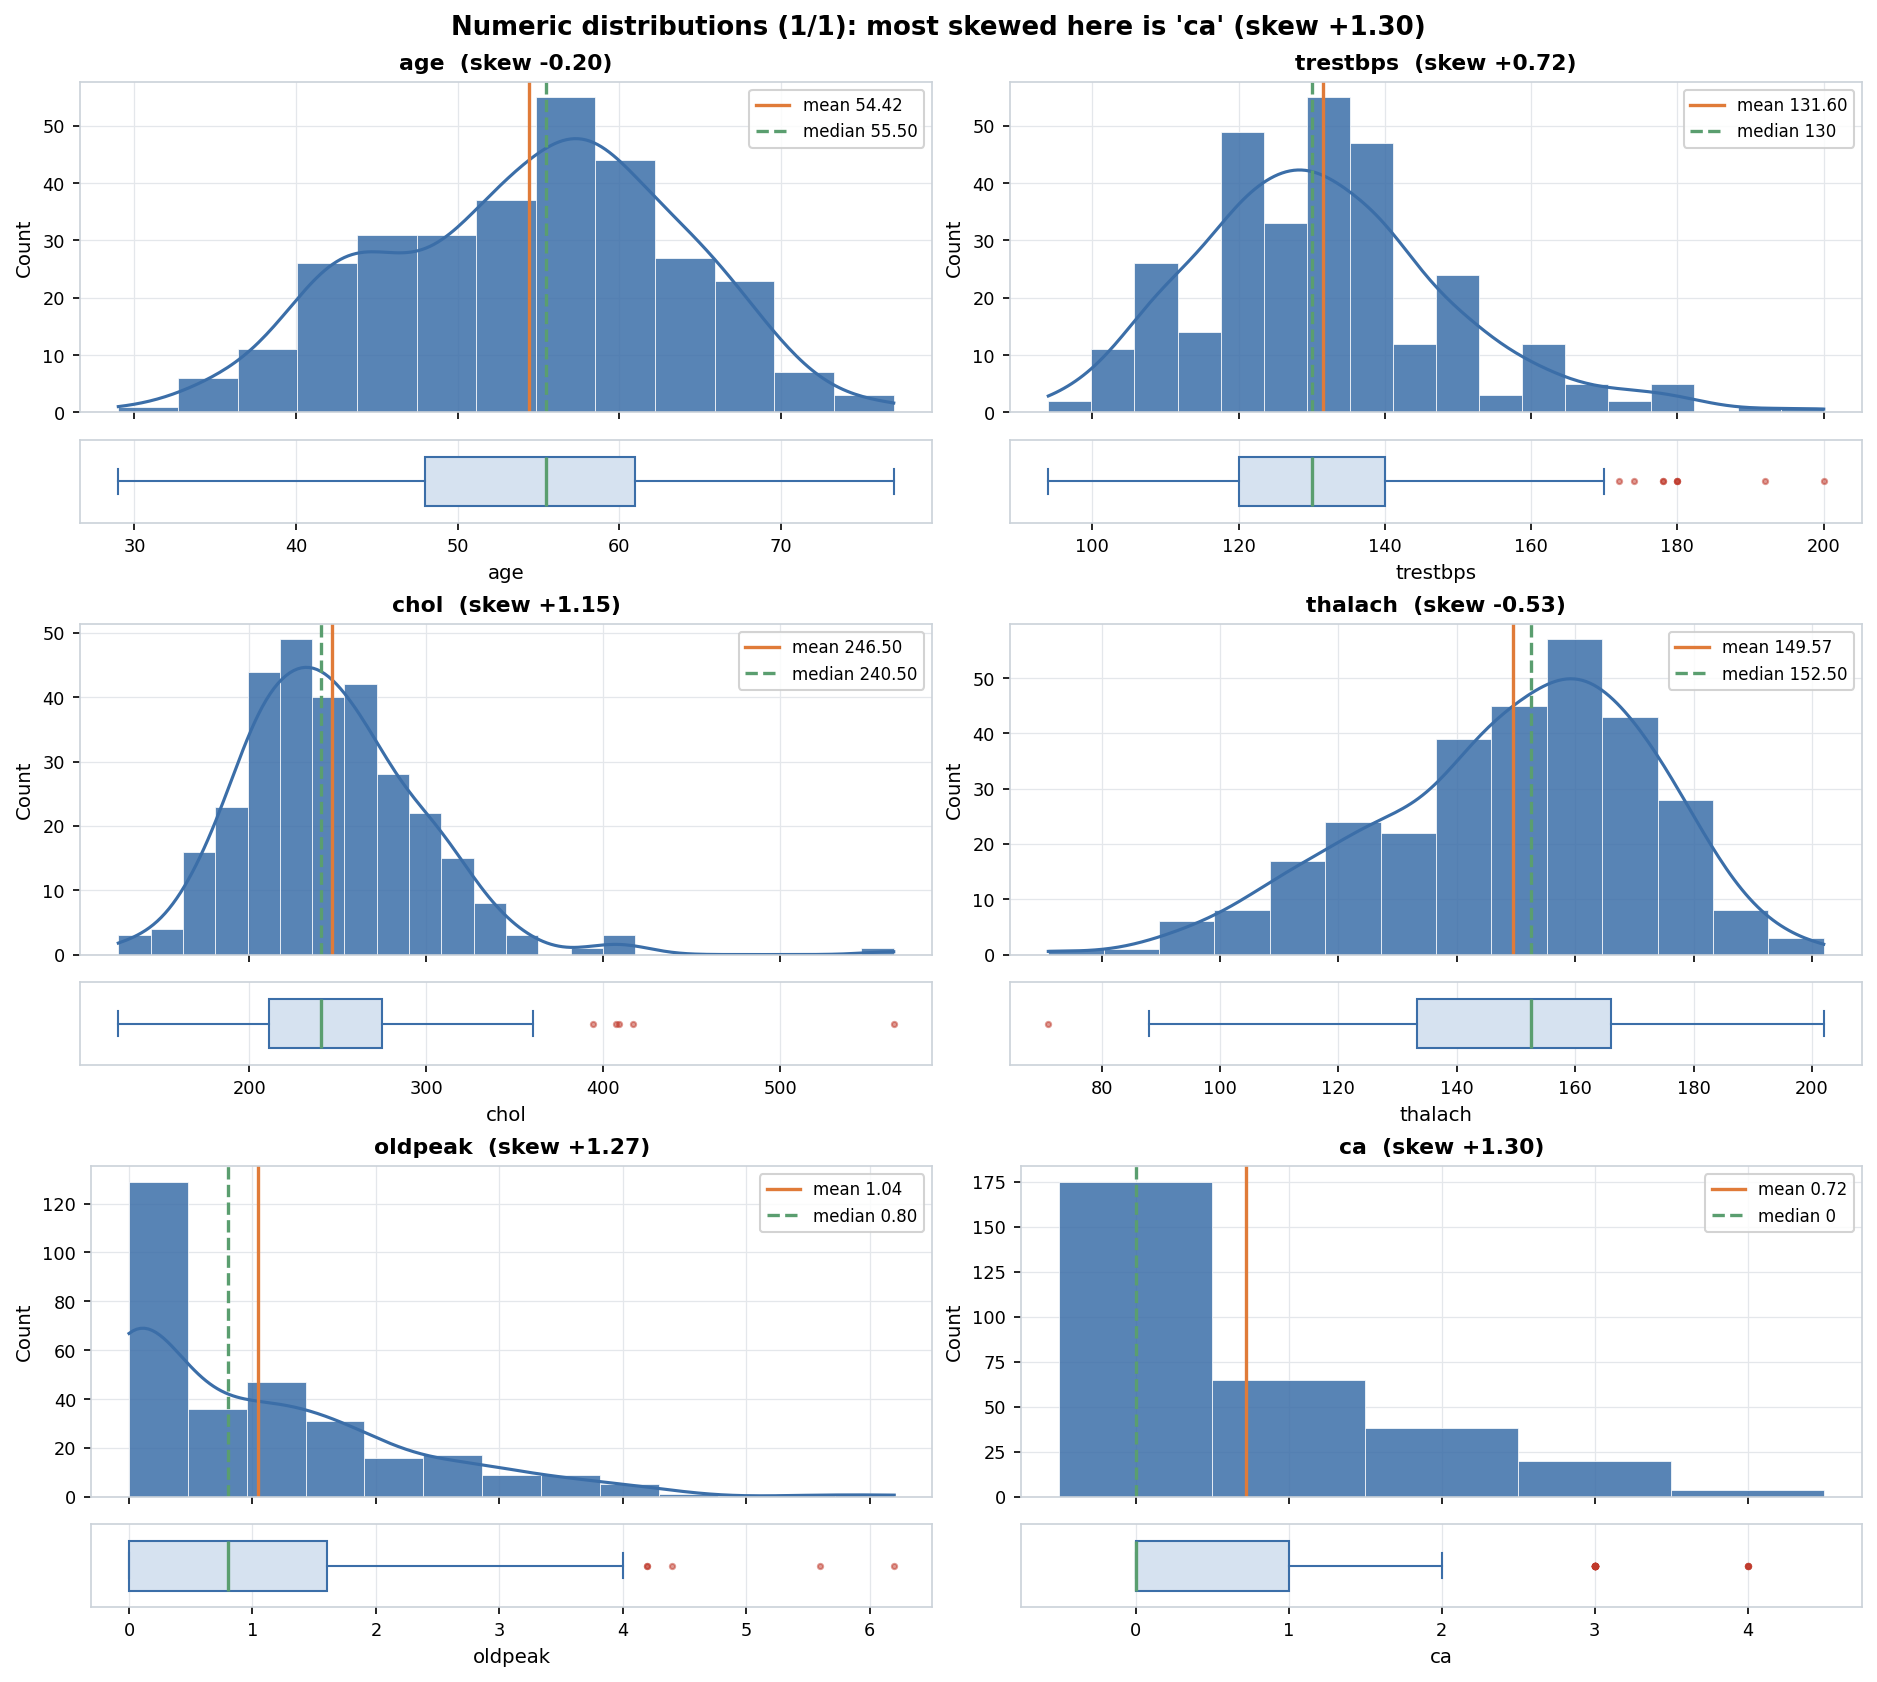

#### 'ca' is right-skewed (skew +1.30) and has 8.0% IQR outliers
*Figure 3. 'ca' is right-skewed (skew +1.30) and has 8.0% IQR outliers.* Close-up of a skewed or outlier-heavy column. The right panel shows the same values on a log1p scale.


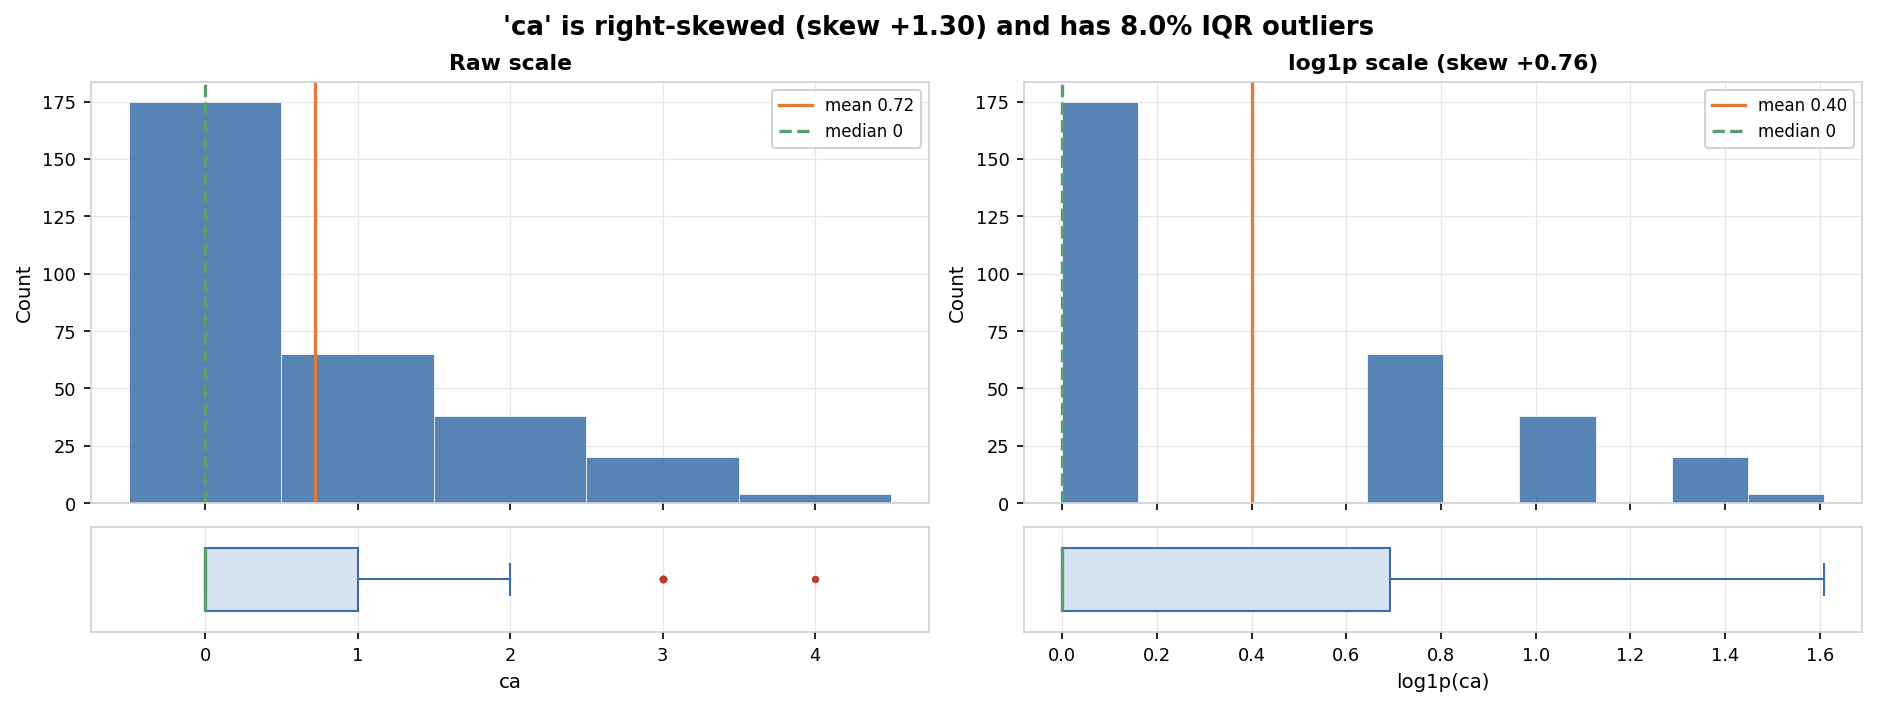

#### 'oldpeak' is right-skewed (skew +1.27)
*Figure 4. 'oldpeak' is right-skewed (skew +1.27).* Close-up of a skewed or outlier-heavy column. The right panel shows the same values on a log1p scale.


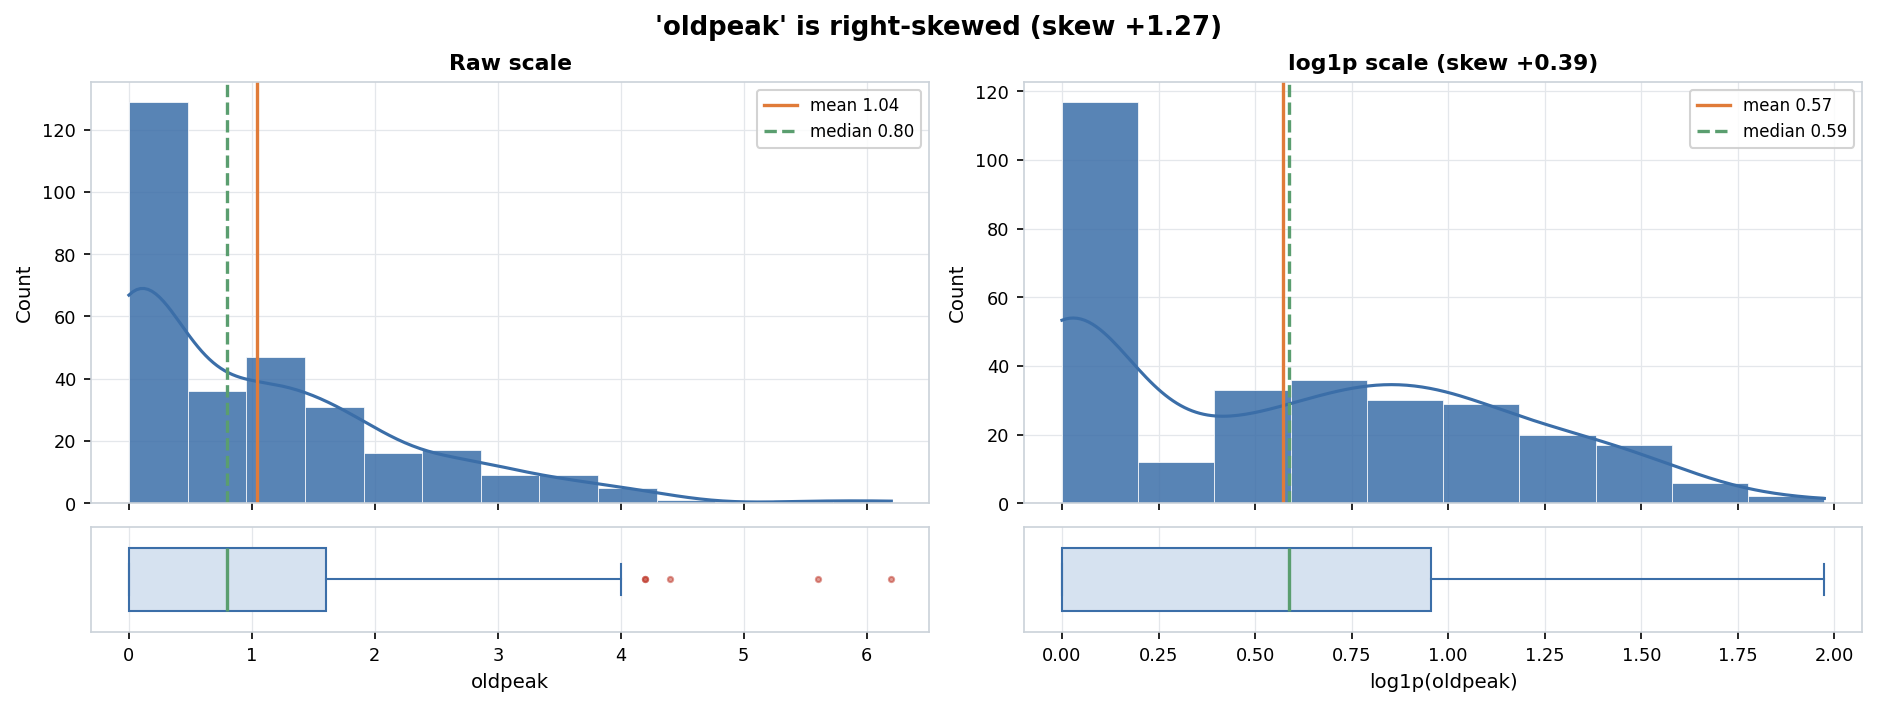

#### 'chol' is right-skewed (skew +1.15)
*Figure 5. 'chol' is right-skewed (skew +1.15).* Close-up of a skewed or outlier-heavy column. The right panel shows the same values on a log1p scale.


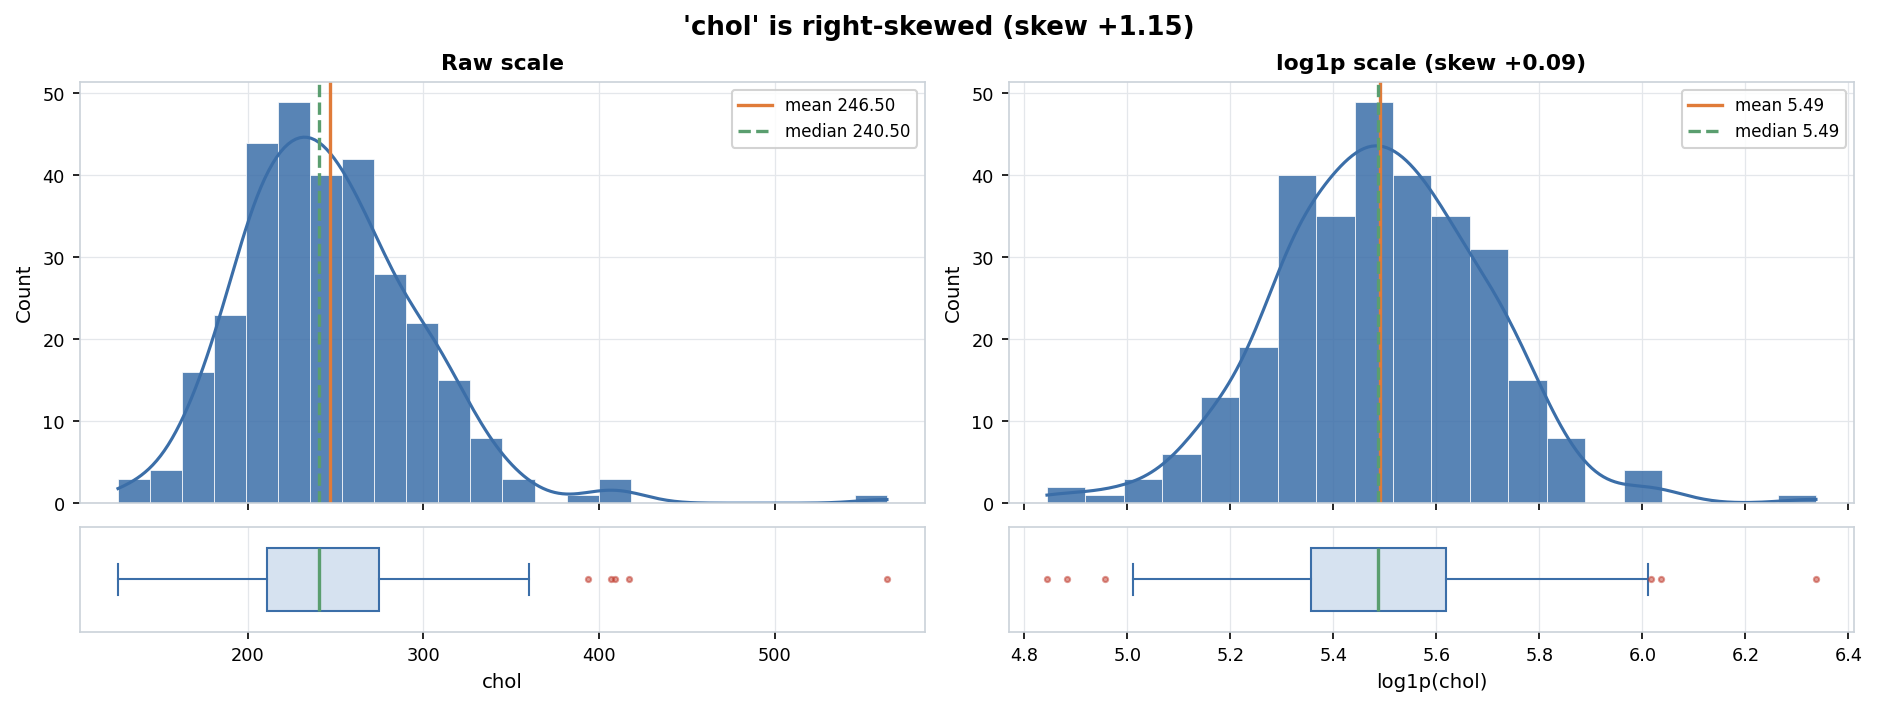

#### 'ca' has the most IQR outliers (8.0% of its values)
*Figure 6. 'ca' has the most IQR outliers (8.0% of its values).* Share of each numeric column's values outside 1.5×IQR. Outliers are only flagged, not removed, in the conservative cleaned data. Red bars are above the guide line.


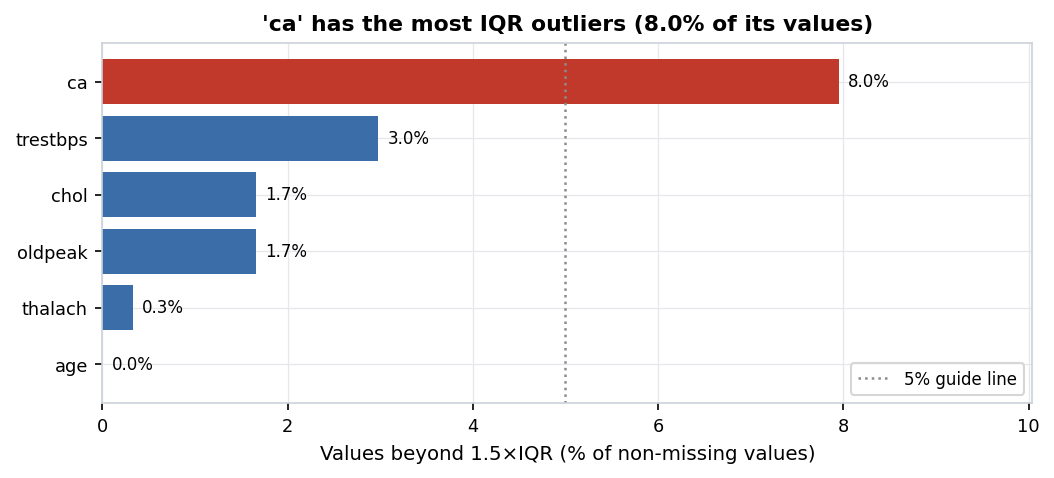

#### Categorical distributions (1/2): most lopsided here is 'fbs' (top level 85.1%)
*Figure 7. Categorical distributions (1/2): most lopsided here is 'fbs' (top level 85.1%).* Share of rows per level (top 15 levels; the rest are grouped as 'Other'). The orange bar marks the smallest (minority) level.


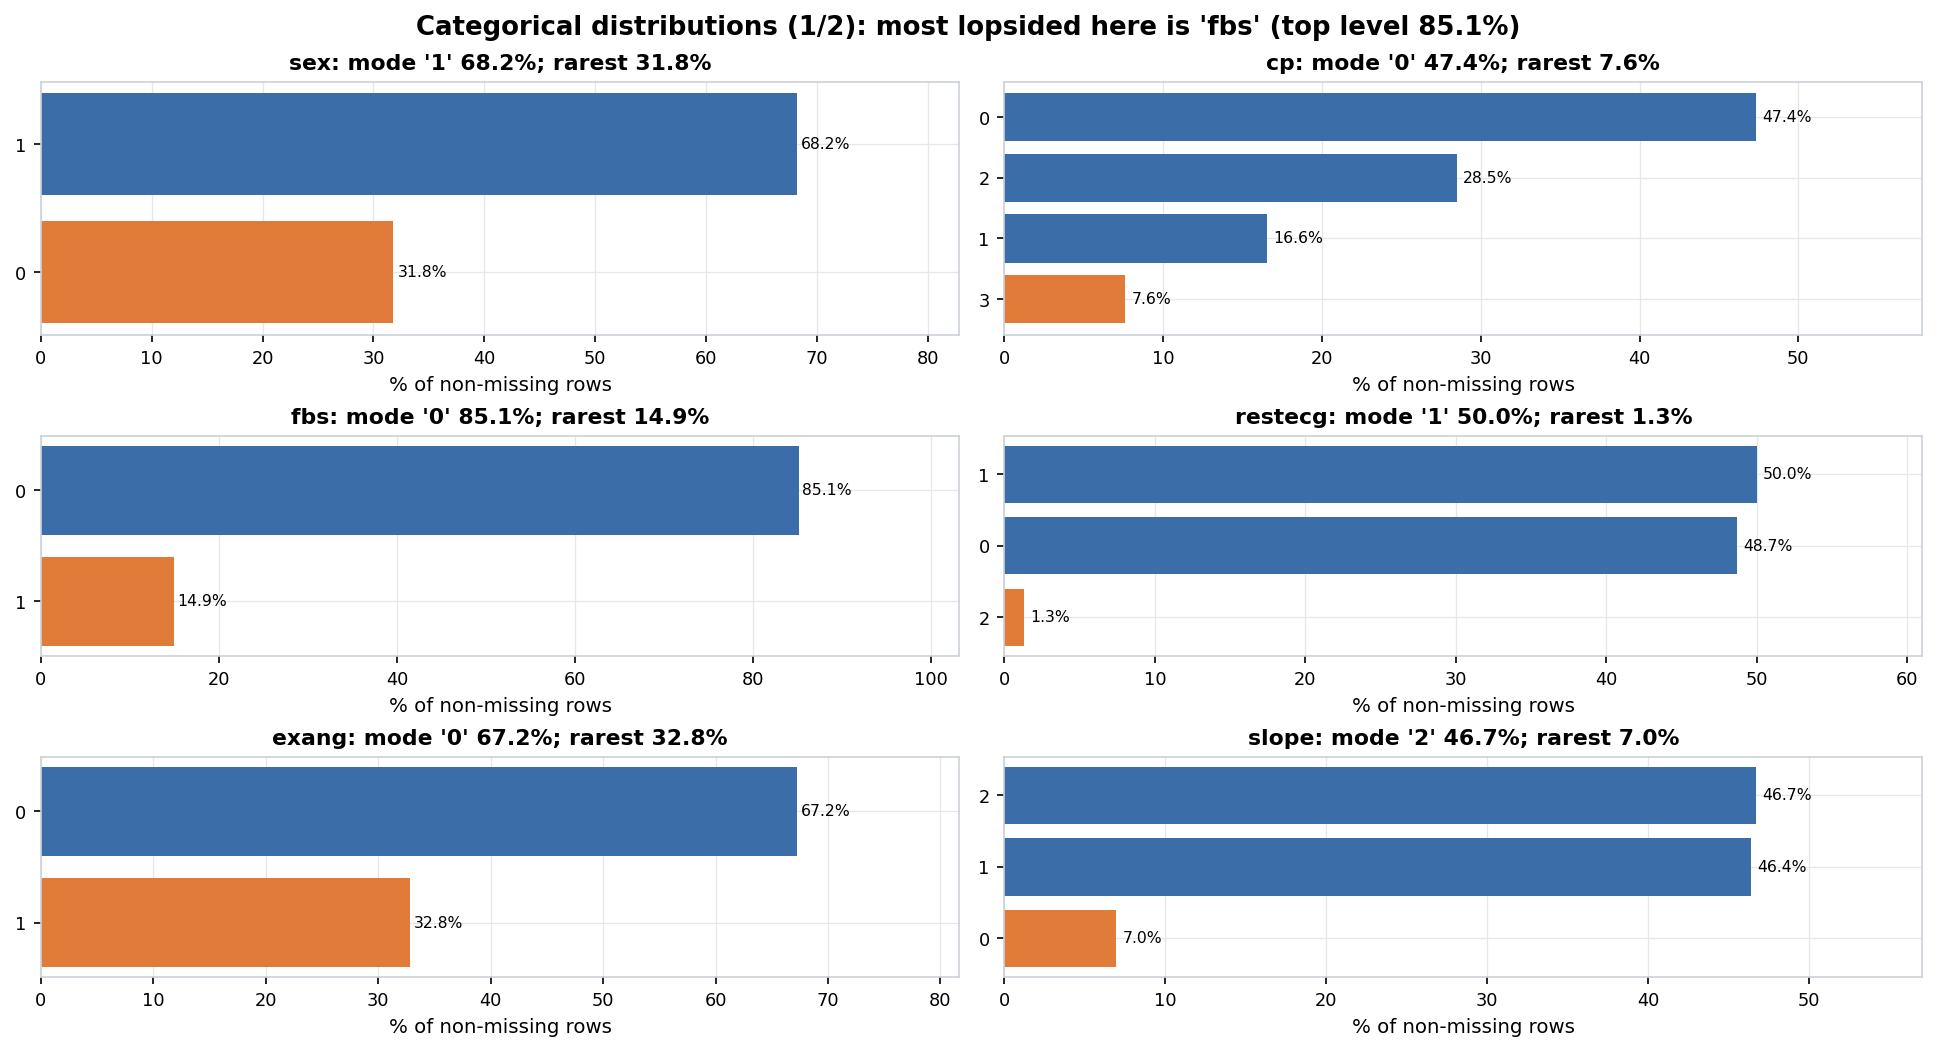

#### Categorical distributions (2/2): most lopsided here is 'thal' (top level 54.6%)
*Figure 8. Categorical distributions (2/2): most lopsided here is 'thal' (top level 54.6%).* Share of rows per level (top 15 levels; the rest are grouped as 'Other'). The orange bar marks the smallest (minority) level.


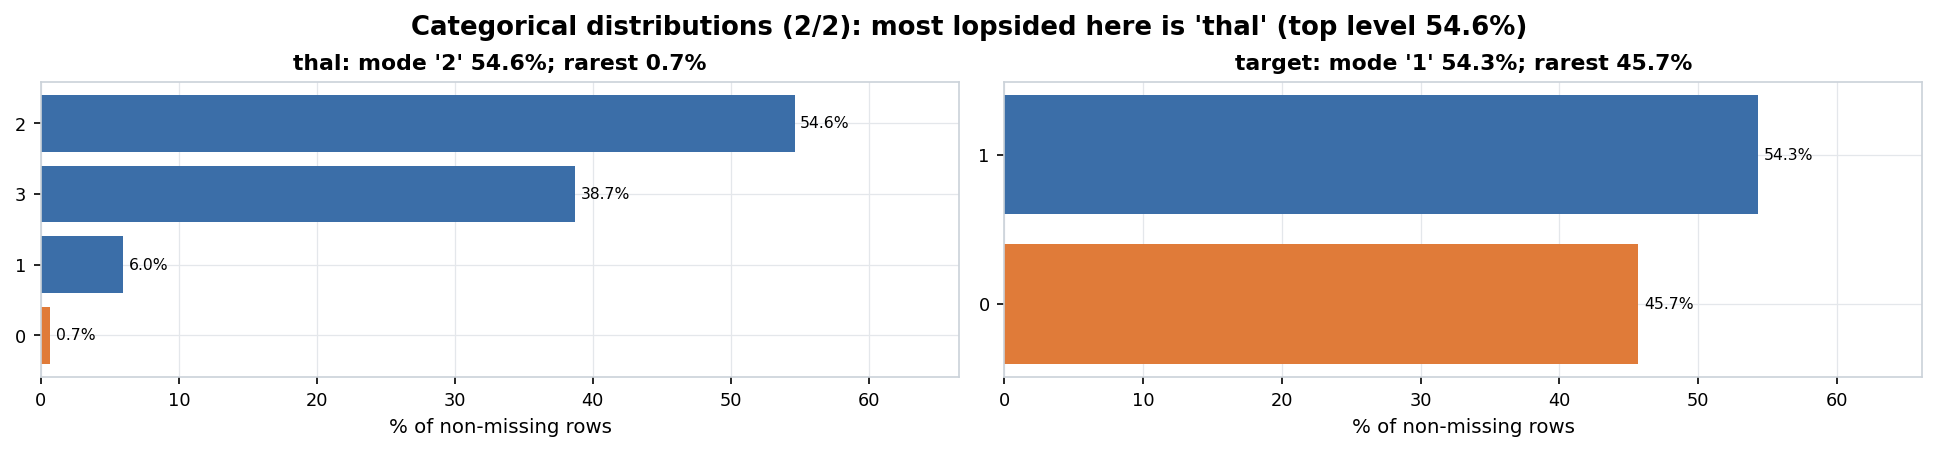

#### 'cp' has the most levels (4)
*Figure 9. 'cp' has the most levels (4).* Number of distinct values in each categorical or binary column.


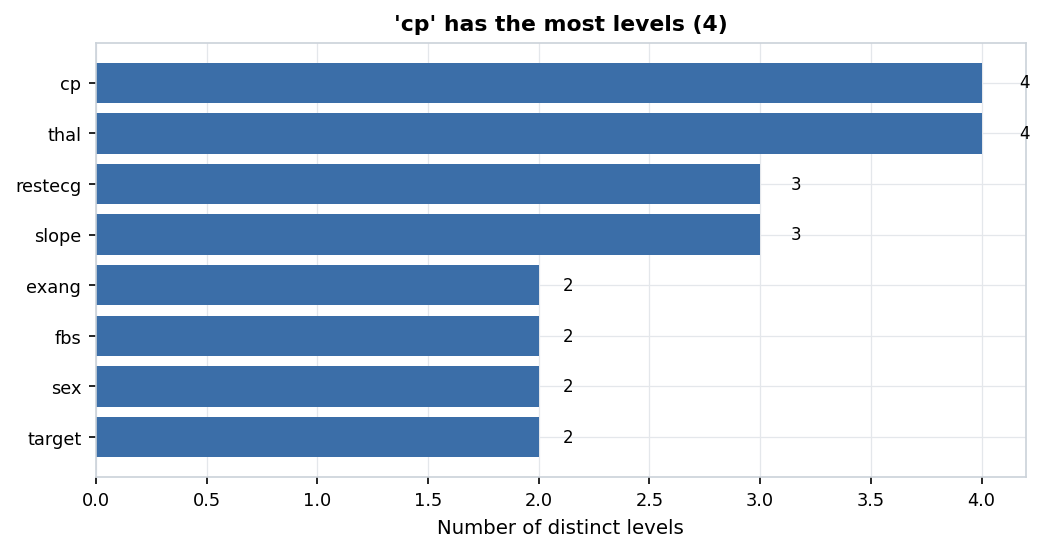

#### Target 'target' is balanced: smallest class '0' is 45.7% of rows (ratio 1.19:1)
*Figure 10. Target 'target' is balanced: smallest class '0' is 45.7% of rows (ratio 1.19:1).* Rows per target class. The orange bar is the smallest class. Highly imbalanced = smallest class under 10% of rows; mildly = largest/smallest ratio of 1.5 or more.


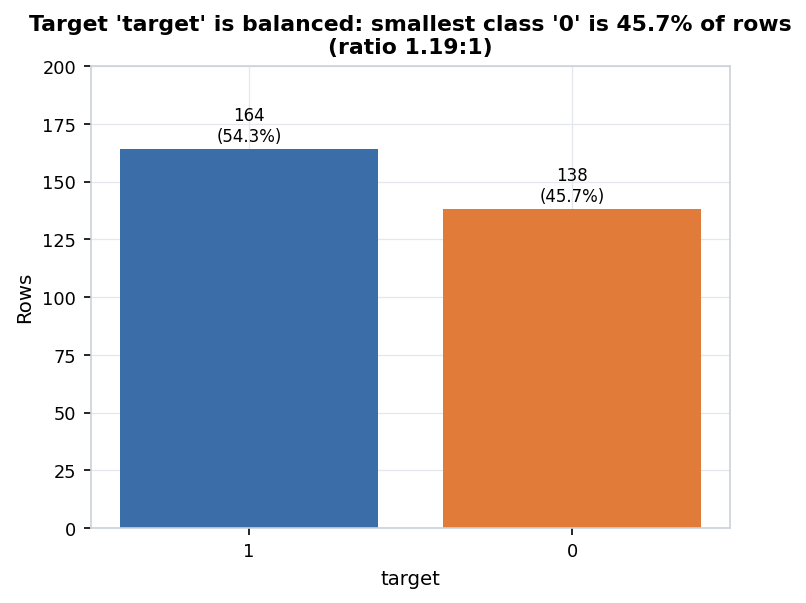

#### The 'target' mix changes most across levels of 'thal' (Cramér's V 0.52)
*Figure 11. The 'target' mix changes most across levels of 'thal' (Cramér's V 0.52).* Share of each target class within each level of the categorical features most associated with the target (bias-corrected Cramér's V). Descriptive coefficients only; no hypothesis tests were run.


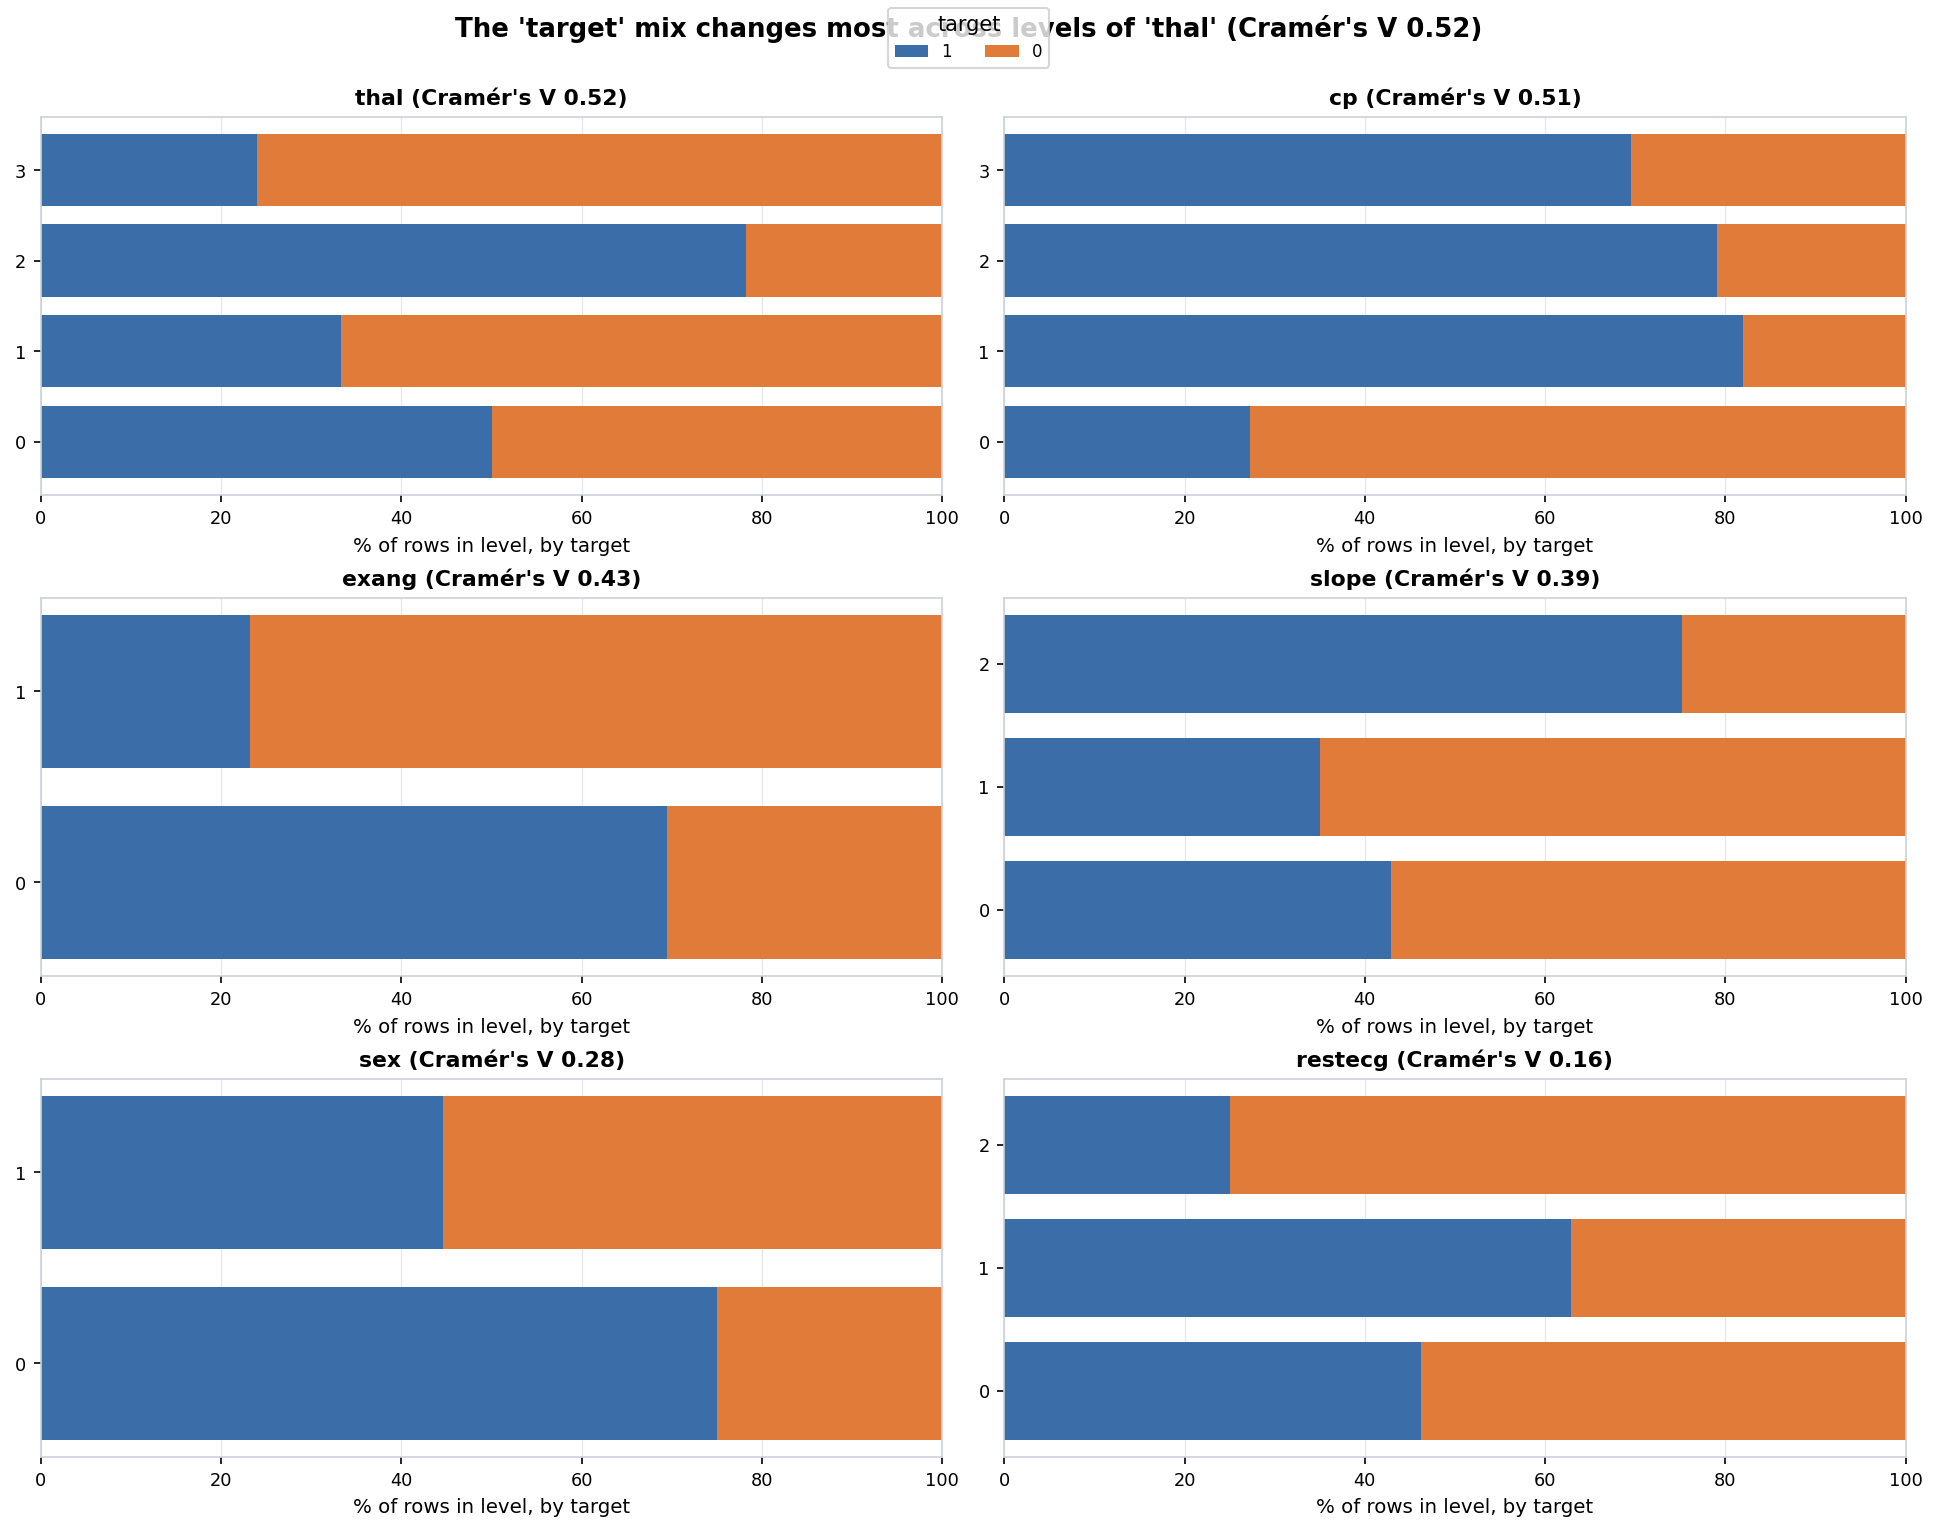

#### Strongest numeric pair: 'thalach' vs 'oldpeak' (Spearman -0.43, Pearson -0.34)
*Figure 12. Strongest numeric pair: 'thalach' vs 'oldpeak' (Spearman -0.43, Pearson -0.34).* Correlation between numeric columns (lower triangle). Left: Pearson (linear). Right: Spearman (rank-based). Descriptive coefficients only; no hypothesis tests were run.


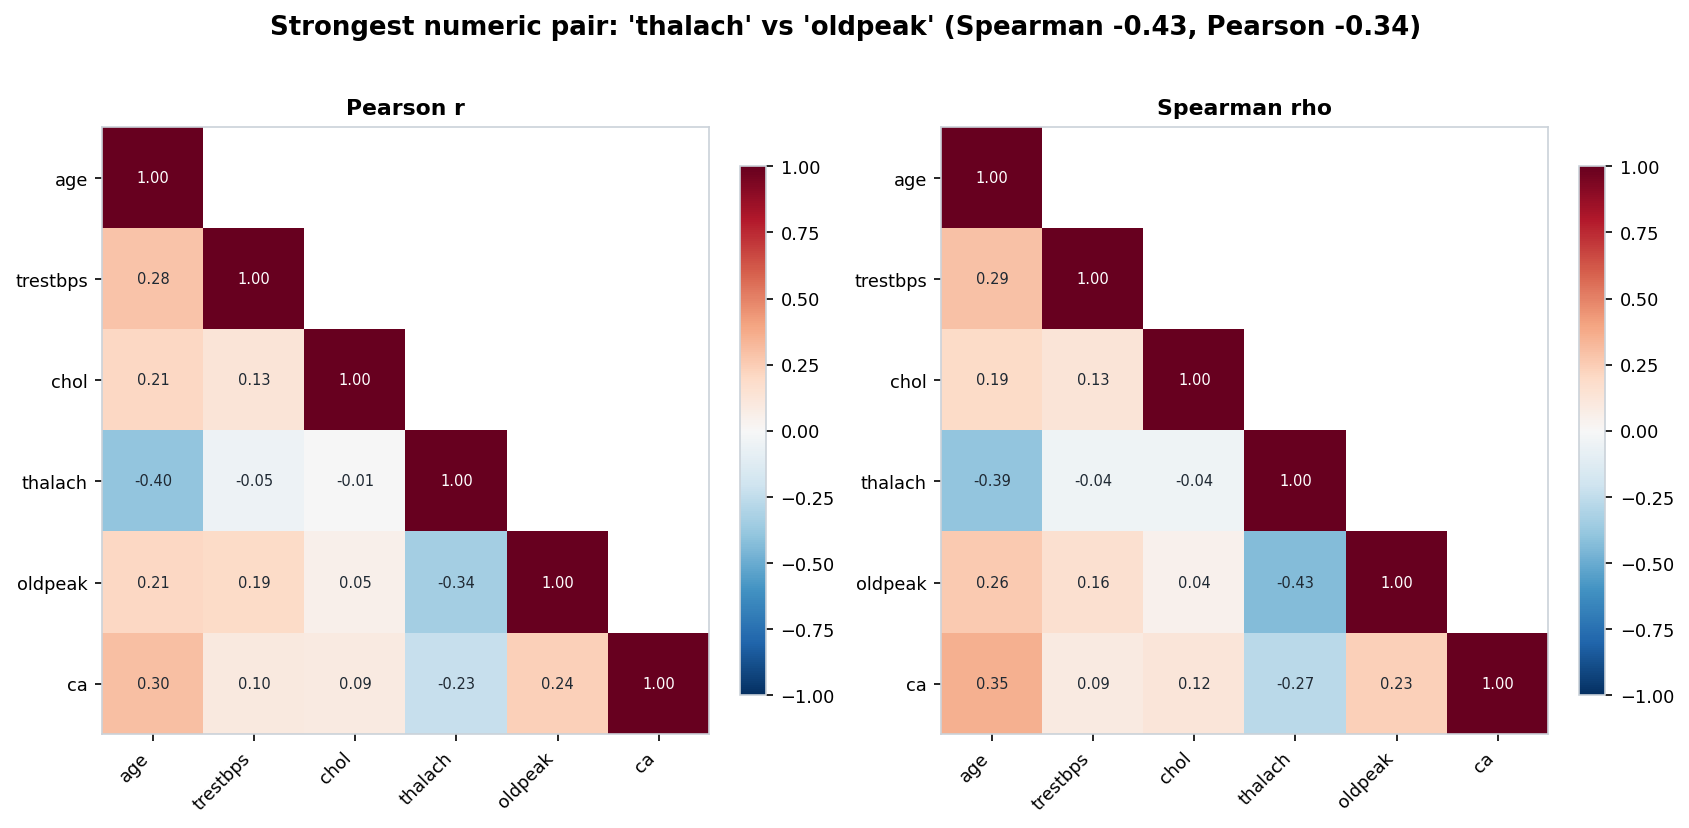

#### Top 6 numeric pairs by |Spearman rho|
*Figure 13. Top 6 numeric pairs by |Spearman rho|.* Scatter plots with a straight-line fit for the most strongly related numeric pairs. Large datasets are randomly sampled for plotting. Descriptive coefficients only; no hypothesis tests were run.


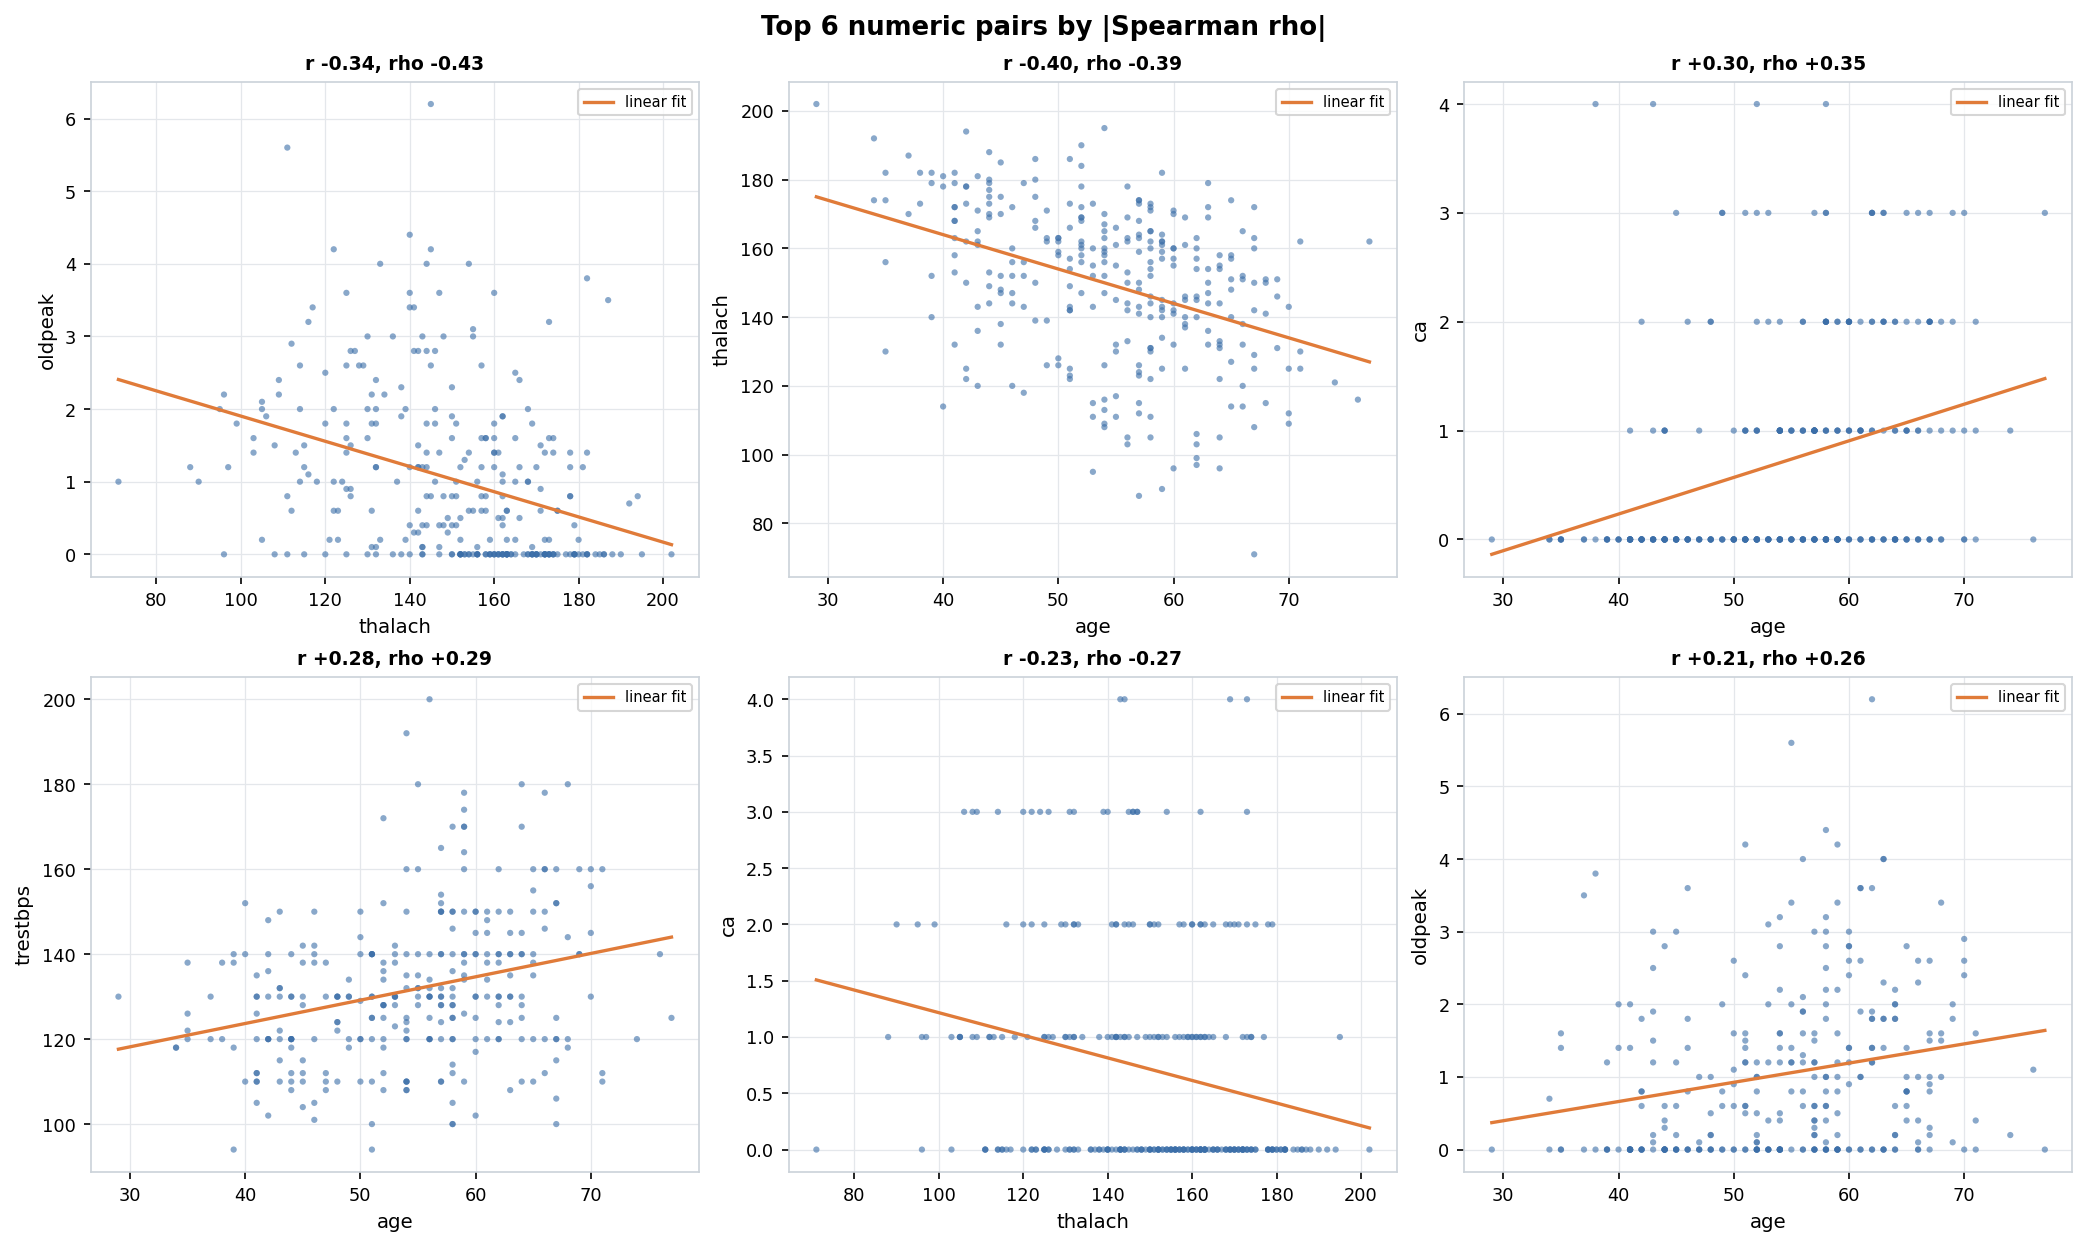

#### 'slope' separates 'oldpeak' the most (eta² 0.33 = share of its spread explained by the groups)
*Figure 14. 'slope' separates 'oldpeak' the most (eta² 0.33 = share of its spread explained by the groups).* Box plots of numeric columns split by categorical columns with up to 8 levels, for the pairs with the largest eta-squared. Descriptive coefficients only; no hypothesis tests were run.


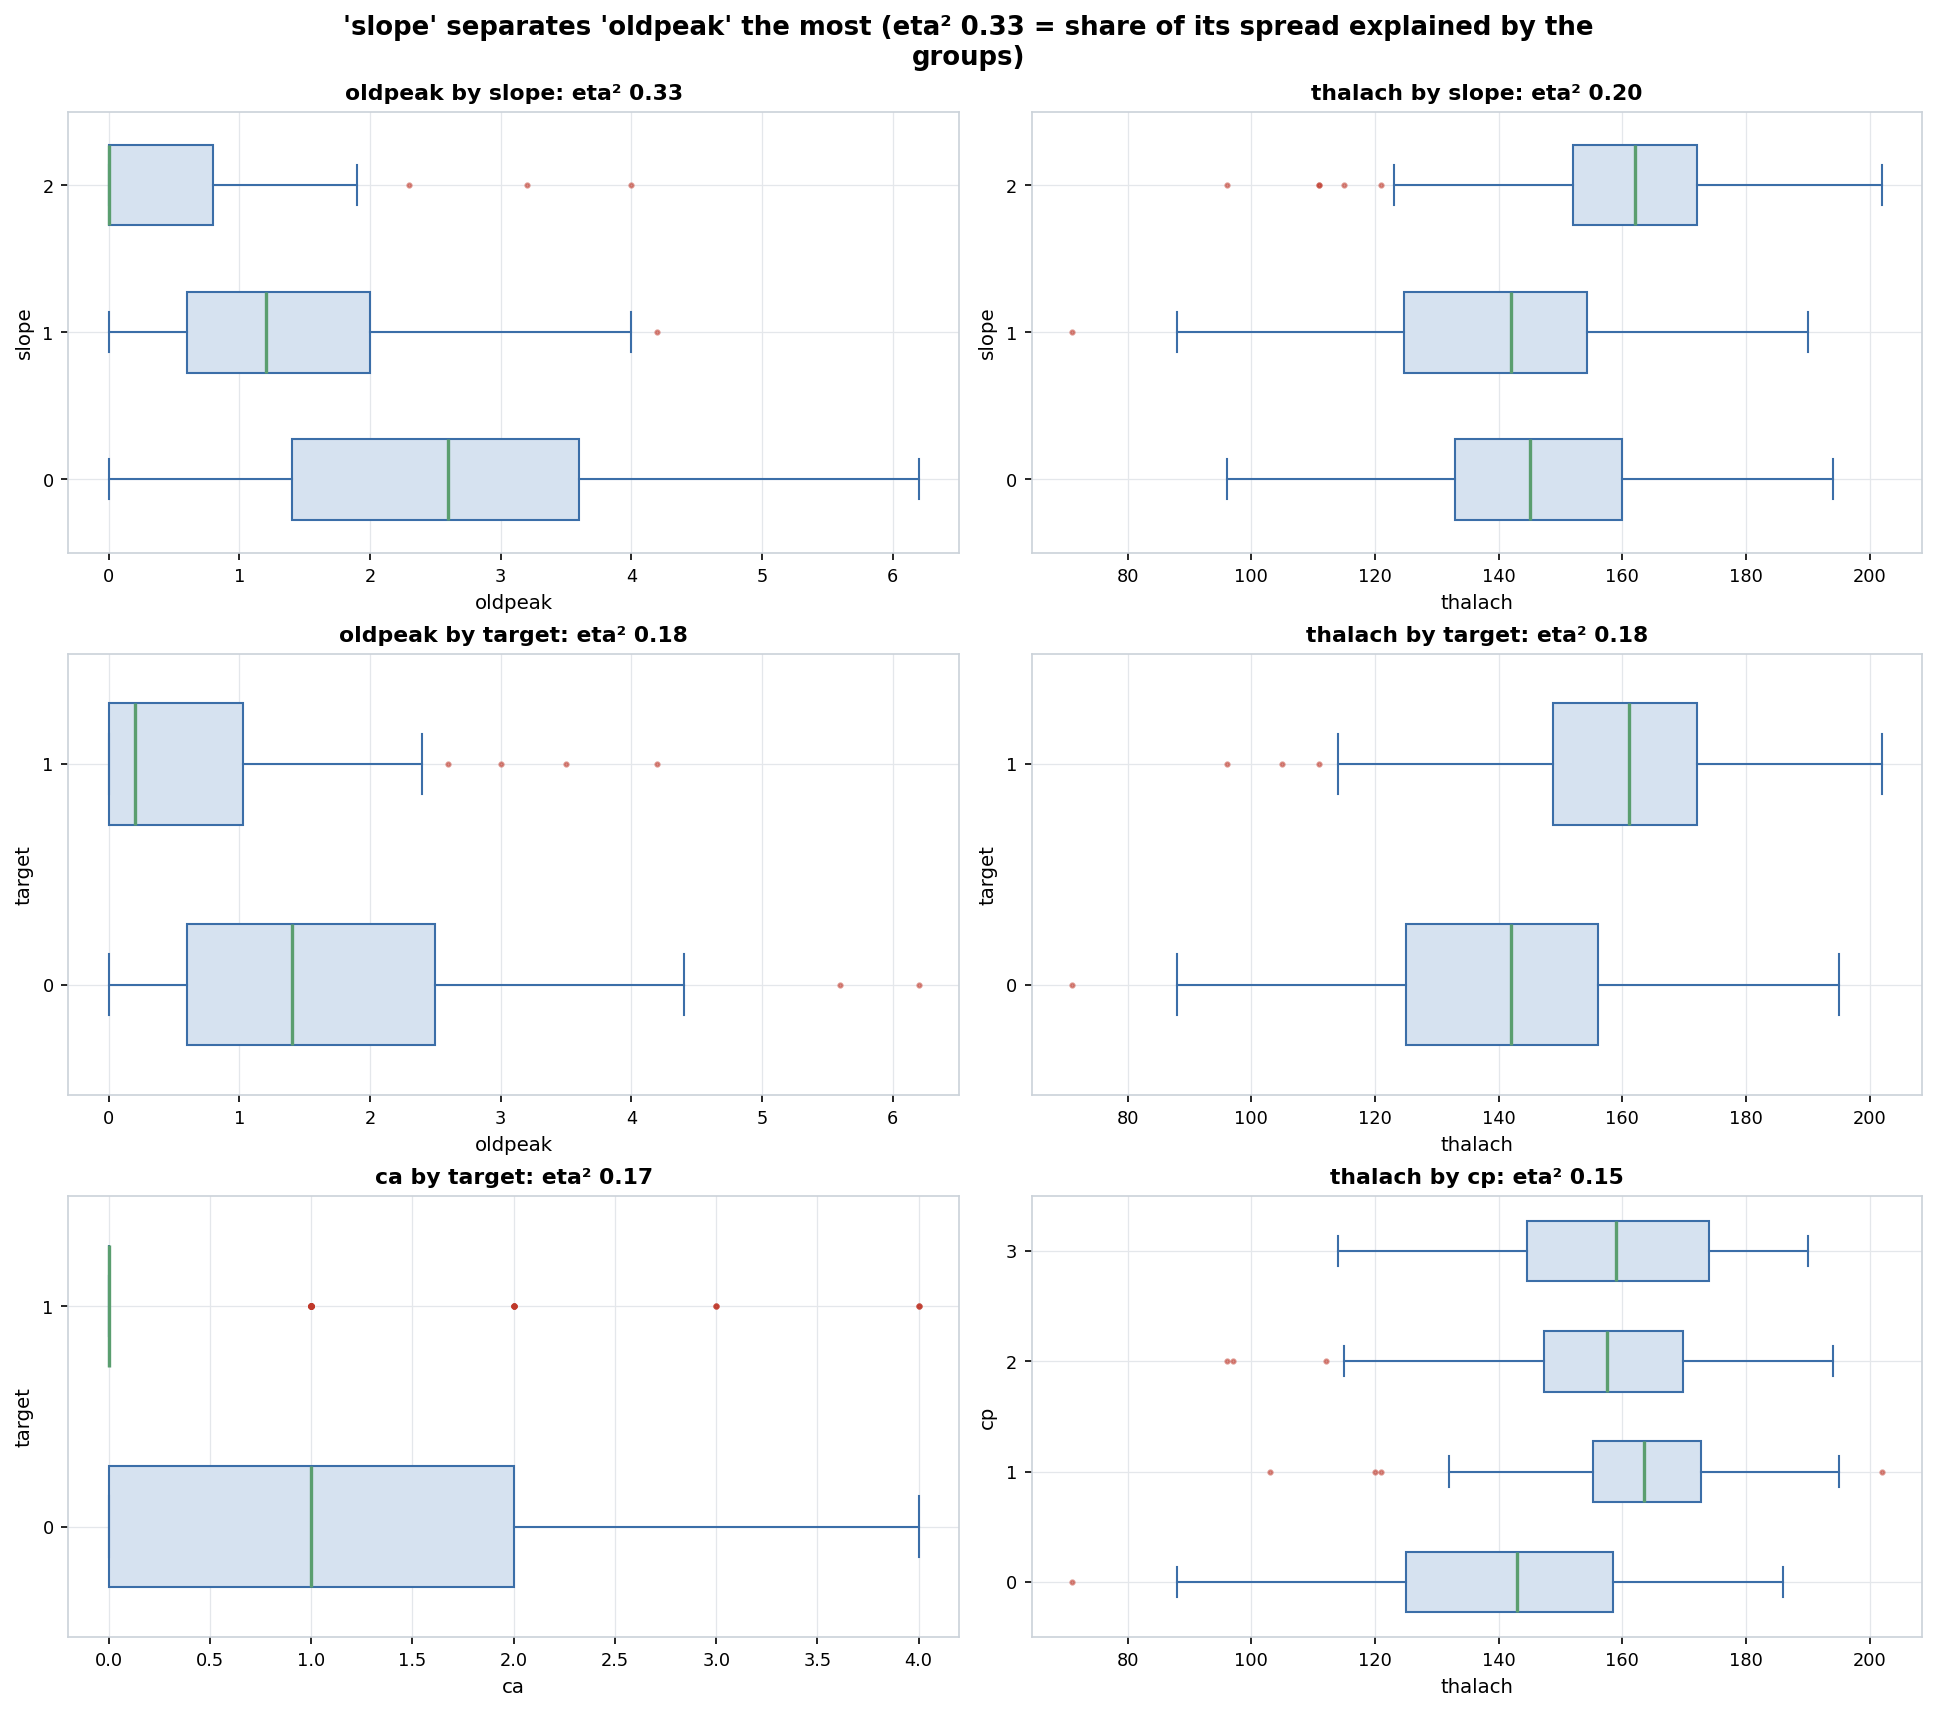

#### Strongest categorical pair: 'thal' vs 'target' (Cramér's V 0.52)
*Figure 15. Strongest categorical pair: 'thal' vs 'target' (Cramér's V 0.52).* Bias-corrected Cramér's V between categorical/binary columns: 0 = unrelated, 1 = one fully predicts the other. Descriptive coefficients only; no hypothesis tests were run.


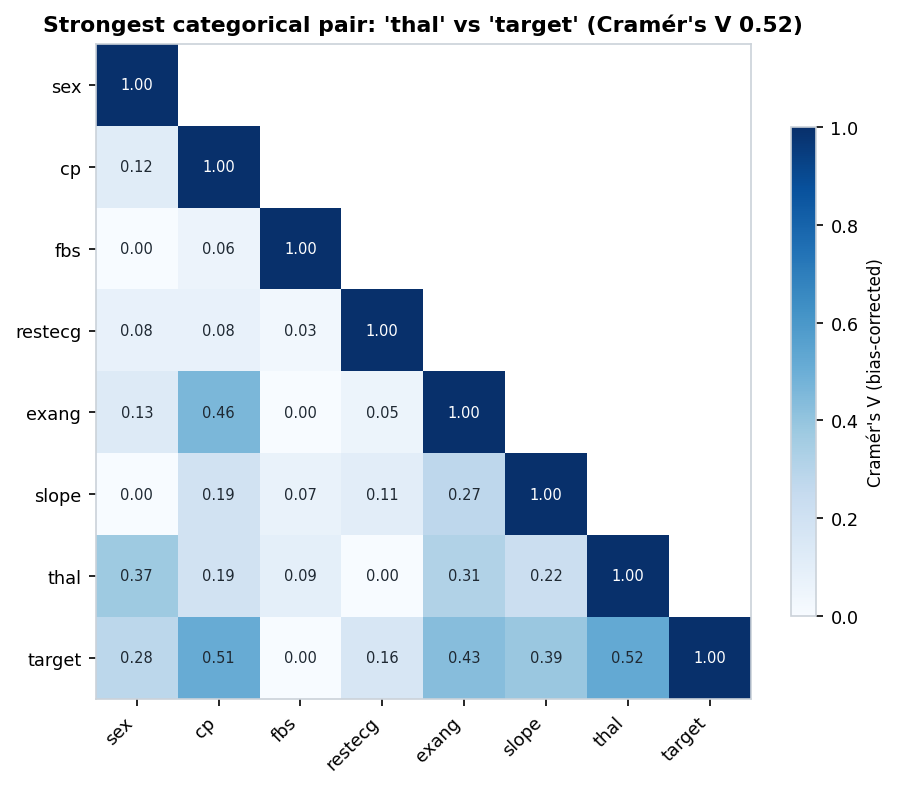

#### Level-by-level mix for the most associated categorical pairs
*Figure 16. Level-by-level mix for the most associated categorical pairs.* For each level of the first column, the share of rows in each level of the second column. Descriptive coefficients only; no hypothesis tests were run.


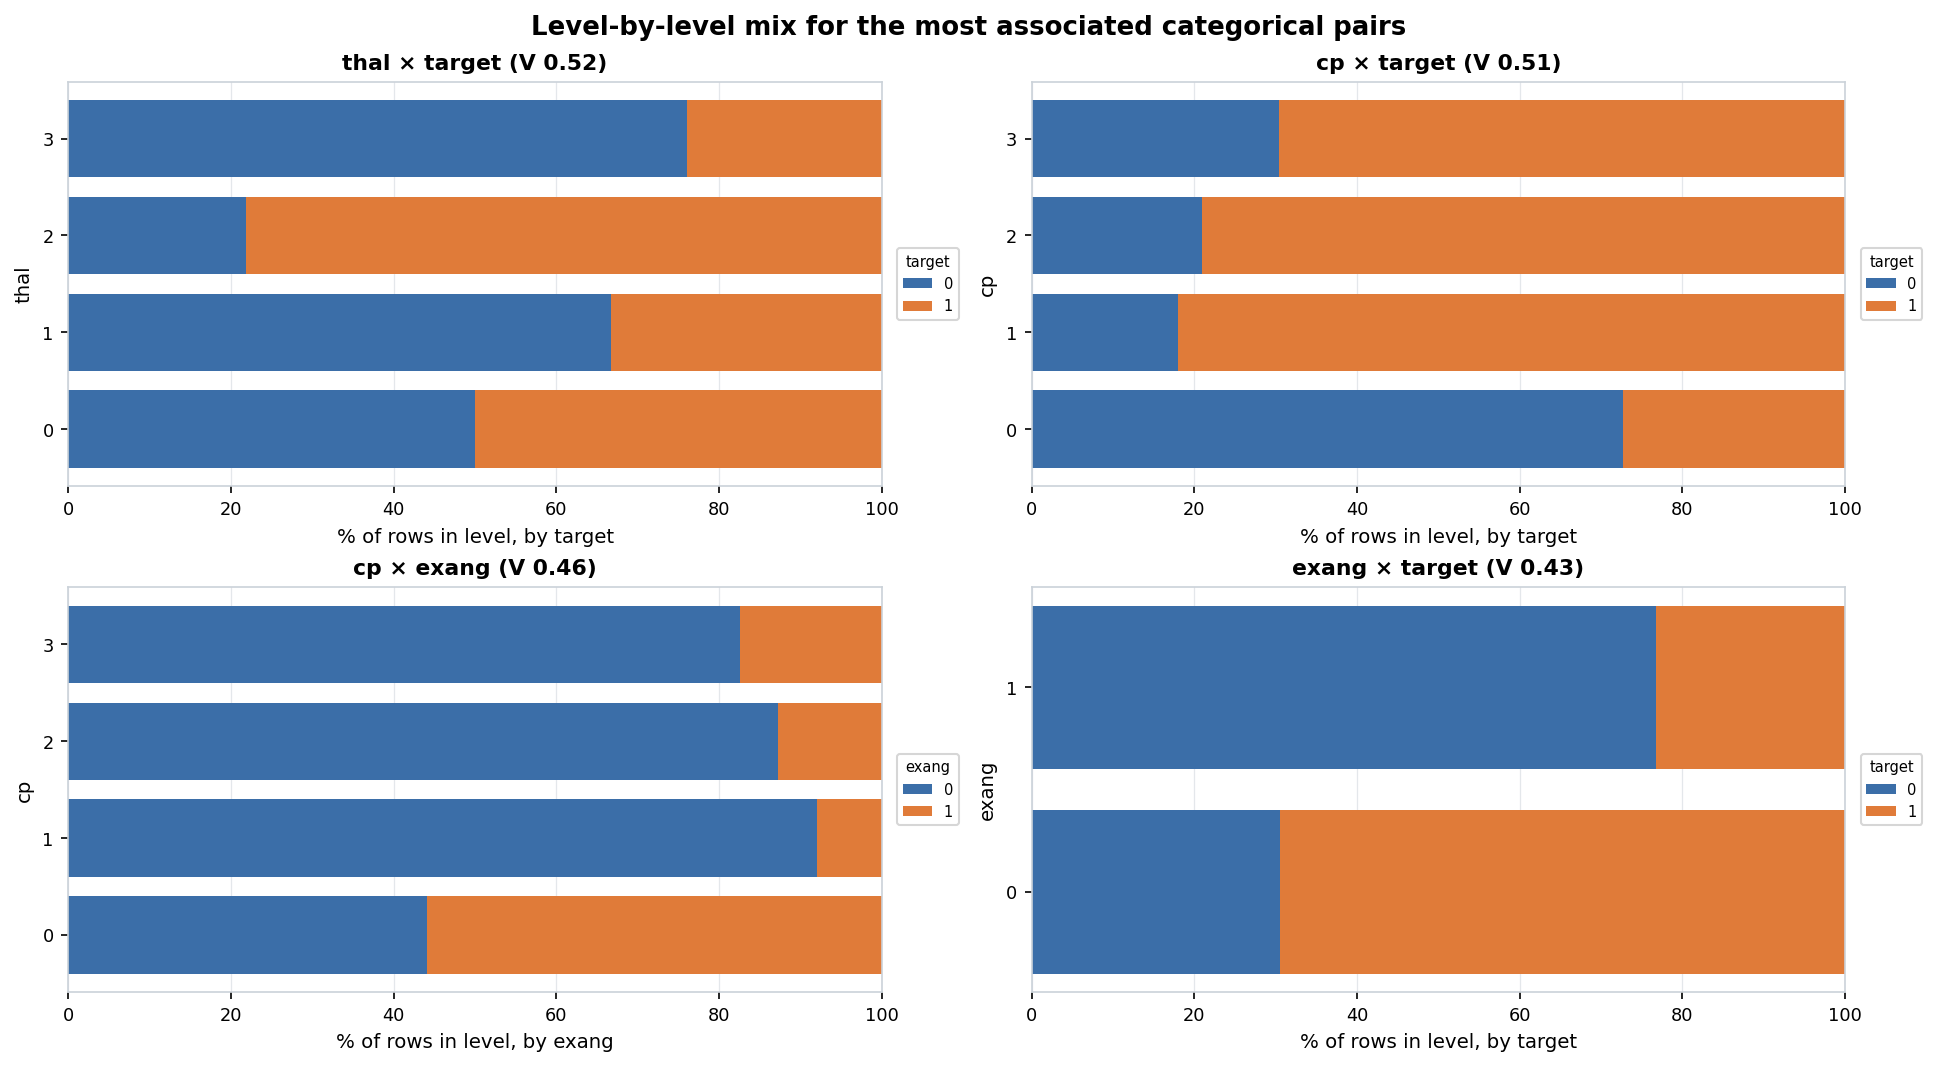

#### 'thal' has the strongest association with 'target' (Cramér's V 0.52)
*Figure 17. 'thal' has the strongest association with 'target' (Cramér's V 0.52).* Every feature ranked by a descriptive association with the target. Different measures are used for different column types, so compare bars of the same colour most directly. Descriptive coefficients only; no hypothesis tests were run.


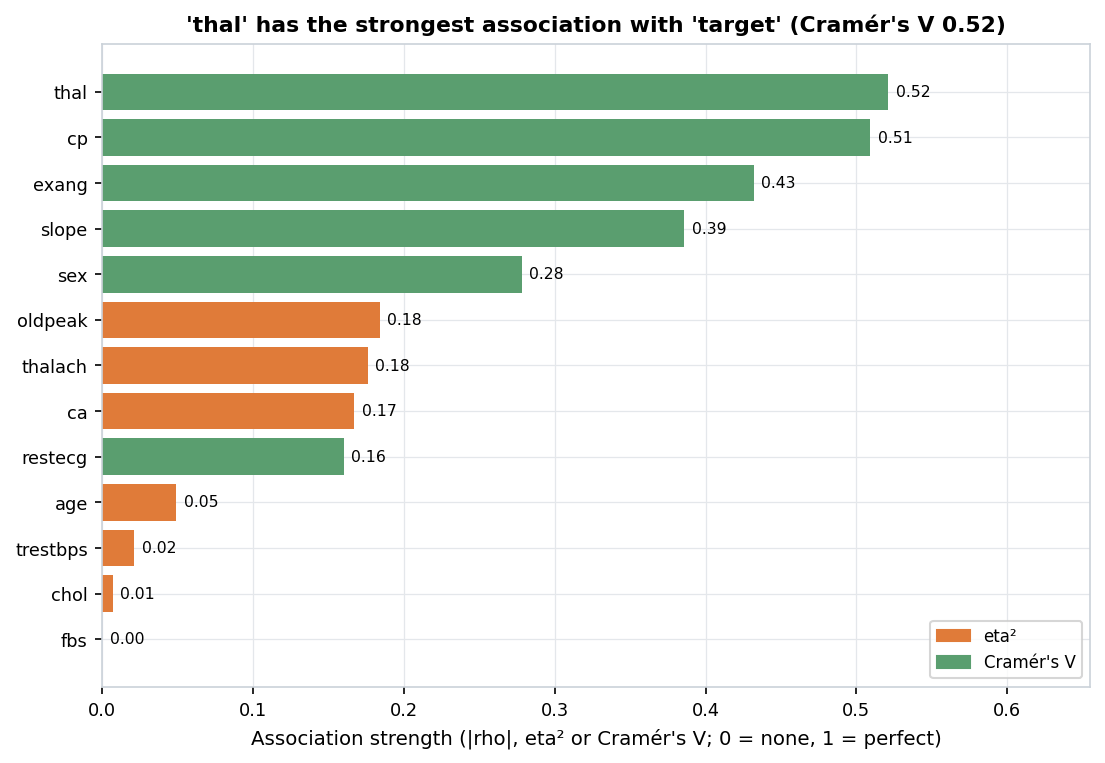

In [4]:
# Display all generated EDA figures and their interpretive captions from outputs/<dataset>/figures/
for png_path in sorted((OUT_DIR / "figures").glob("*.png")):
    display(Markdown(f"### `{png_path.name}`"))
    display(Image(filename=str(png_path)))

## 5. Normalization & Scaling Analysis
**What we did & why:** We evaluated skewness and scale disparity across all numeric columns (`ads.scaling.analyze_scaling`). Right-skewed positive columns (`|skew| > 1.0`, `min >= 0`) are recommended for `log1p` transformation, skewed columns with negative values use `yeo_johnson`, and high scale disparity triggers `zscore` standardization in `<dataset>_scaled.csv` for scale-sensitive models while keeping the primary cleaned dataset unscaled.

In [5]:
display(Markdown((OUT_DIR / "scaling_report.md").read_text(encoding="utf-8")))

# Scaling & Transformation Analysis — `heart_disease`

## Decision Summary

> Primary cleaned output is **not** scaled. The Phase 3 test library is rank-based or scale-invariant (Welch/Mann-Whitney, Spearman, Kruskal, chi-square), so scaling would not change results. Log transforms are recommended for columns [chol, oldpeak, ca] only for plotting and for parametric/regression use. A scaled copy is provided for TA review and for any future modeling.

## Scale Disparity Across Numeric Features

- **Max standard deviation:** `51.7535`
- **Min standard deviation:** `1.0067`
- **Scale disparity ratio (`max_std / min_std`):** `51.41x`
- **Z-score standardization recommended for scale-sensitive models (PCA/L1/L2/KNN):** `True`

## Per-Column Transformation Recommendations

| Column | Skewness | Kurtosis | Min | Max | Std | Min >= 0 | Recommended Transform | Reason |
| :--- | ---: | ---: | ---: | ---: | ---: | :---: | :--- | :--- |
| `age` | -0.204 | -0.528 | 29 | 77 | 9.048 | True | `none` | Moderate/low skewness (skew=-0.20); no non-linear transform needed. |
| `trestbps` | 0.717 | 0.923 | 94 | 200 | 17.563 | True | `none` | Moderate/low skewness (skew=0.72); no non-linear transform needed. |
| `chol` | 1.147 | 4.543 | 126 | 564 | 51.753 | True | `log1p` | Right-skewed (skew=1.15 > 1.0) with non-negative domain (min=126); log1p recommended. |
| `thalach` | -0.533 | -0.062 | 71 | 202 | 22.904 | True | `none` | Moderate/low skewness (skew=-0.53); no non-linear transform needed. |
| `oldpeak` | 1.266 | 1.568 | 0 | 6.2 | 1.161 | True | `log1p` | Right-skewed (skew=1.27 > 1.0) with non-negative domain (min=0); log1p recommended. |
| `ca` | 1.296 | 0.781 | 0 | 4 | 1.007 | True | `log1p` | Right-skewed (skew=1.30 > 1.0) with non-negative domain (min=0); log1p recommended. |

## Generated Convenience Artifacts

- **Scaled CSV (TA review / downstream modeling copy):** `data\cleaned\heart_disease_scaled.csv`


## 6. Key Findings: Automated & Analyst Manual Insights
**What we did & why:** `ads.insights.generate_insights` evaluates deterministic rules across 7 categories (Data Quality, Distributions, Class Balance, Relationships, Cardinality/Structure, Scaling, and Modeling/Testing Implications), backing every number with an `evidence` dictionary in `insights.json`, while preserving our human-written domain analysis in the `MANUAL` block.

In [6]:
display(Markdown((OUT_DIR / "insights.md").read_text(encoding="utf-8")))

# Dataset Insights — `heart_disease`

_The automated insights below are generated by fixed rules from computed values (no LLM). Each number is stored with its evidence in `insights.json`. Relationship numbers are descriptive only; no hypothesis tests were run in Phase 1._

## Automated insights

### Data quality

- **MEDIUM** — 1 exact duplicate rows were removed (the first copy of each was kept).

### Distributions

- **MEDIUM** — 'ca' has many outliers: 7.95% of its values (n = 24) are beyond 1.5×IQR. They are flagged, not removed. ([figure](figures/outlier_summary.png))
- **MEDIUM** — 'ca' is right-skewed (skew = 1.3): its median (0) is below its mean (0.72), so a log transform is advisable for plots and parametric models. ([figure](figures/numeric_detail_ca.png))
- **MEDIUM** — 'chol' is right-skewed (skew = 1.15): its median (240.5) is below its mean (246.5), so a log transform is advisable for plots and parametric models. ([figure](figures/numeric_detail_chol.png))
- **MEDIUM** — 'oldpeak' is right-skewed (skew = 1.27): its median (0.8) is below its mean (1.04), so a log transform is advisable for plots and parametric models. ([figure](figures/numeric_detail_oldpeak.png))
- **MEDIUM** — 'ca' is zero-inflated: 57.95% of its values are exactly zero. ([figure](figures/numeric_detail_ca.png))
- **MEDIUM** — 'oldpeak' is zero-inflated: 32.45% of its values are exactly zero. ([figure](figures/numeric_detail_oldpeak.png))
- **LOW** — 'age' may have 2 peaks (simple histogram heuristic), which can mean mixed sub-groups; check the plot. ([figure](figures/numeric_distributions_1.png))

### Class balance

- **INFO** — Target 'target' is balanced: the smallest class '0' is 45.7% of rows and the largest '1' is 54.3% (the largest class is 1.19 times the smallest). ([figure](figures/target_balance.png))

### Relationships (descriptive)

- **MEDIUM** — The categorical feature most associated with target 'target' is 'thal' (Cramér's V = 0.52; descriptive). ([figure](figures/target_relationships.png))
- **LOW** — Groups of 'slope' differ in 'oldpeak': the groups explain 33% of its variance (eta² = 0.33; descriptive). ([figure](figures/numeric_by_category.png))
- **LOW** — Groups of 'slope' differ in 'thalach': the groups explain 20% of its variance (eta² = 0.2; descriptive). ([figure](figures/numeric_by_category.png))
- **LOW** — 'age' and 'ca' rise together (Spearman rho = +0.35, Pearson r = +0.3; descriptive). ([figure](figures/top_scatter_pairs.png))
- **LOW** — 'age' and 'thalach' move in opposite directions (Spearman rho = -0.39, Pearson r = -0.4; descriptive). ([figure](figures/top_scatter_pairs.png))
- **LOW** — 'thalach' and 'oldpeak' move in opposite directions (Spearman rho = -0.43, Pearson r = -0.34; descriptive). ([figure](figures/top_scatter_pairs.png))
- **LOW** — The numeric feature most associated with target 'target' is 'oldpeak' (eta² = 0.18; descriptive). ([figure](figures/target_relationships.png))

### Cardinality and structure

- **LOW** — 'thal' has 1 level(s) under 1% of rows (e.g. '0', n = 2); these will give sparse cells in later chi-square tests (Phase 3). ([figure](figures/categorical_distributions_2.png))
- **LOW** — 'restecg' has a level with only 4 rows ('2'), under the 20-row guide for group comparisons. ([figure](figures/categorical_distributions_1.png))

### Scaling notes

- **INFO** — Numeric columns differ a lot in spread (largest std is 51.41 times the smallest); z-scores are advised only for scale-sensitive methods such as regularized regression, distance-based methods or PCA.
- **INFO** — Scaling note: log1p is recommended for 'ca' (skew = 1.3) for plots and parametric models only; the main cleaned file is not transformed.
- **INFO** — Scaling note: log1p is recommended for 'chol' (skew = 1.15) for plots and parametric models only; the main cleaned file is not transformed.
- **INFO** — Scaling note: log1p is recommended for 'oldpeak' (skew = 1.27) for plots and parametric models only; the main cleaned file is not transformed.

### Implications for later testing

- **MEDIUM** — Rank-based methods (Spearman, Mann-Whitney, Kruskal-Wallis) are recommended for 3 skewed or outlier-heavy column(s): 'ca', 'chol', 'oldpeak'.

## Manual insights (written by the analyst)

<!-- MANUAL:START -->
- **Integer-encoded nominal categories (`cp`, `restecg`, `slope`, `thal`):** In raw UCI Heart Disease files, chest pain type (`cp`: 0-3), resting ECG (`restecg`: 0-2), ST segment slope (`slope`: 0-2), and thalassemia (`thal`: 0-3) are stored as small integers. Treating them as continuous counts would compute meaningless linear correlations; our `heart_disease.yaml` overrides them to `categorical_nominal`.
- **Data collection quirk in `ca` and `thal`:** In the 303-row Cleveland UCI split, `thal == 0` (2 rows) and `ca == 4` (5 rows) correspond to coded missing values (`?` in the original UCI `.data` file) that were exported as integer codes when converted to CSV.
- **Zero-inflated ST depression (`oldpeak`):** 32.8% of patients have `oldpeak == 0.0` (no exercise-induced ST depression), producing strong zero-inflation and right skewness (`skew = +1.27`). Rank-based non-parametric tests (Mann-Whitney U) are strongly preferred over two-sample t-tests for `oldpeak`.
- **Extreme cholesterol outlier (`chol = 564 mg/dL`):** A single postmenopausal female patient exhibits `chol = 564 mg/dL` (well above the $3.0\times\text{IQR}$ fence), which is a clinically plausible familial hypercholesterolemia value and is rightly flagged rather than deleted.
- **Duplicate record removed:** 1 exact duplicate row (`age=38, sex=1, cp=2, trestbps=138, chol=175, ...`) was detected and removed (`303 -> 302` rows).
- **Target findings for Phase 5 benchmark recovery:** (1) `thal <-> target` (Cramér's $V = 0.52$), (2) `cp <-> target` (Cramér's $V = 0.51$), (3) `exang <-> target` (Cramér's $V = 0.43$), (4) `oldpeak <-> target` (Spearman $\rho = -0.43$), (5) `thalach <-> target` (Spearman $\rho = +0.43$), and (6) `ca <-> target` (Spearman $\rho = -0.46$).
<!-- MANUAL:END -->
